# Chapter 03 제출 답안. 데이터의 첫인상 읽기

## 0. 제출 정보
- 이름: 장태진
- GitHub ID: Taejin-AI
- 최종 제출 URL: https://github.com/Taejin-AI/llm-data-analysis-study/blob/master/chapter03/chapter03.ipynb

> 이 Notebook은 공식 `ch03_data_overview.ipynb`를 처음부터 끝까지 실행한 뒤, 21절에서 추가 검증을 직접 실행했고, 마지막에 답안(1~6)을 정리했습니다.

# 3장. 데이터의 첫인상 읽기

이 노트북은 강의안 `book/chapters/ch03_data_first_impression.md`를 따라가며 직접 실행해 보는 실습용 자료입니다.

이번 장의 목표는 멋진 분석 결과를 바로 만드는 것이 아니라, 분석 전에 데이터가 어떤 모양인지 차분히 확인하는 습관을 만드는 것입니다. 코드를 한 셀씩 실행하면서 출력 결과를 보고, 바로 아래 설명과 질문에 답해 보세요.


## 0. 이번 장에서 확인할 것

데이터를 처음 열었을 때는 다음 질문에 답할 수 있어야 합니다.

- 데이터 파일은 몇 개인가?
- 각 파일은 어떤 역할을 하는가?
- 각 파일은 몇 행, 몇 열로 구성되어 있는가?
- 어떤 컬럼이 있고, 각 컬럼은 어떤 의미를 가지는가?
- 숫자, 문자, 날짜 컬럼은 무엇인가?
- 비어 있는 값이나 중복된 값은 없는가?
- 여러 파일을 연결할 수 있는 기준 컬럼은 무엇인가?
- LLM이 설명한 데이터 구조가 실제 데이터와 일치하는가?


![CSV 파일을 pandas DataFrame으로 불러오는 흐름](images/ch03_csv_to_dataframe_flow.svg)

CSV 파일은 텍스트 파일이지만, pandas로 불러오면 행과 열을 가진 `DataFrame`으로 다룰 수 있습니다.


## 1. 실습 준비

먼저 필요한 패키지를 불러오고, 프로젝트 폴더와 데이터 폴더를 찾습니다. 노트북을 `notebooks` 폴더에서 실행해도 되고, 프로젝트 루트에서 실행해도 되도록 `find_project_root()` 함수를 사용합니다.


In [1]:
from pathlib import Path

import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)


def find_project_root(start: Path) -> Path:
    """현재 위치에서 위로 올라가며 data/raw 폴더가 있는 프로젝트 루트를 찾습니다."""
    start = start.resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "raw").exists() and (candidate / "book").exists():
            return candidate
    raise FileNotFoundError("프로젝트 루트를 찾지 못했습니다. 노트북을 저장소 안에서 실행해 주세요.")


PROJECT_ROOT = find_project_root(Path.cwd())
DATA_DIR = PROJECT_ROOT / "data" / "raw"

print("프로젝트 루트:", PROJECT_ROOT)
print("데이터 폴더:", DATA_DIR)


프로젝트 루트: C:\dev\llm-data-analysis-course
데이터 폴더: C:\dev\llm-data-analysis-course\data\raw


## 2. 데이터 파일이 있는지 확인하기

파일 경로 오류는 초보자가 가장 자주 만나는 오류입니다. 데이터를 불러오기 전에 필요한 CSV 파일이 실제로 있는지 먼저 확인합니다.


In [2]:
expected_files = [
    "customers.csv",
    "products.csv",
    "orders.csv",
    "order_items.csv",
]

file_check = pd.DataFrame({
    "file": expected_files,
    "path": [str(DATA_DIR / filename) for filename in expected_files],
    "exists": [(DATA_DIR / filename).exists() for filename in expected_files],
})

file_check


,file,path,exists
0,customers.csv,C:\dev\llm-data-analysis-course\data\raw\custo...,True
1,products.csv,C:\dev\llm-data-analysis-course\data\raw\produ...,True
2,orders.csv,C:\dev\llm-data-analysis-course\data\raw\order...,True
3,order_items.csv,C:\dev\llm-data-analysis-course\data\raw\order...,True


`exists`가 모두 `True`이면 다음 단계로 진행할 수 있습니다.

하나라도 `False`라면 데이터가 아직 생성되지 않았을 수 있습니다. 그 경우 터미널에서 아래 명령을 실행해 샘플 데이터를 생성합니다.

```bash
python scripts/generate_sample_data.py
```


## 3. CSV 파일을 DataFrame으로 불러오기

이제 4개의 CSV 파일을 pandas `DataFrame`으로 불러옵니다. 각 변수 이름은 파일 이름과 비슷하게 맞춰 두면 이후 코드를 읽기 쉽습니다.


In [3]:
customers = pd.read_csv(DATA_DIR / "customers.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
orders = pd.read_csv(DATA_DIR / "orders.csv")
order_items = pd.read_csv(DATA_DIR / "order_items.csv")

print("customers:", type(customers))
print("products:", type(products))
print("orders:", type(orders))
print("order_items:", type(order_items))


customers: <class 'pandas.DataFrame'>
products: <class 'pandas.DataFrame'>
orders: <class 'pandas.DataFrame'>
order_items: <class 'pandas.DataFrame'>


분석할 데이터셋이 여러 개일 때는 딕셔너리로 묶어 두면 반복 점검을 하기 편합니다.


In [4]:
datasets = {
    "customers": customers,
    "products": products,
    "orders": orders,
    "order_items": order_items,
}

list(datasets.keys())


['customers', 'products', 'orders', 'order_items']

## 4. 각 파일의 역할 이해하기

이번 과정에서 사용하는 데이터는 가상의 온라인 쇼핑몰 운영 데이터입니다.

| 파일 | 역할 | 먼저 확인할 것 |
| --- | --- | --- |
| `customers.csv` | 고객 정보 | 고객 수, 연령, 성별, 지역, 가입일 |
| `products.csv` | 상품 정보 | 상품 수, 카테고리, 가격 |
| `orders.csv` | 주문 정보 | 주문 수, 주문일, 결제수단, 주문상태 |
| `order_items.csv` | 주문 상세 정보 | 주문별 상품, 수량, 단가 |

처음에는 파일을 합치지 말고, 각 파일을 따로 살펴보는 것이 좋습니다.


![pandas DataFrame 구조 예시](images/ch03_dataframe_structure.svg)

DataFrame은 행(row)과 열(column)로 구성됩니다. `shape`, `head()`, `columns`, `info()` 같은 기본 도구를 사용해 구조를 확인합니다.


## 5. 데이터 크기 확인하기

`shape`는 데이터의 행과 열 개수를 알려 줍니다.

- 앞 숫자: 행 개수
- 뒤 숫자: 열 개수

예를 들어 `(150, 6)`은 150행 6열이라는 뜻입니다.


In [5]:
print("customers:", customers.shape)
print("products:", products.shape)
print("orders:", orders.shape)
print("order_items:", order_items.shape)


customers: (150, 6)
products: (100, 4)
orders: (300, 5)
order_items: (764, 5)


In [6]:
shape_summary = pd.DataFrame([
    {
        "dataset": name,
        "rows": df.shape[0],
        "columns": df.shape[1],
    }
    for name, df in datasets.items()
])

shape_summary


,dataset,rows,columns
0,customers,150,6
1,products,100,4
2,orders,300,5
3,order_items,764,5


### 생각해 보기

- 가장 행이 많은 데이터셋은 무엇인가요?
- `order_items`가 `orders`보다 행이 많다면, 그 이유는 무엇일까요?
- 분석 보고서에 데이터 규모를 설명한다면 어떤 문장으로 쓸 수 있을까요?


## 6. 데이터 앞부분과 마지막 부분 보기

`head()`는 앞부분 5행을 보여 줍니다. 컬럼명이 예상과 맞는지, 값의 형태가 자연스러운지 빠르게 확인할 때 사용합니다.


In [7]:
customers.head()


,customer_id,name,gender,age,city,signup_date
0,1,김수민,F,19,광주,2024-06-19
1,2,김정호,F,32,대구,2025-11-02
2,3,이경수,F,61,성남,2024-06-12
3,4,조영호,F,55,울산,2026-04-13
4,5,이예원,F,19,부산,2024-09-13


In [8]:
products.head()


,product_id,product_name,category,price
0,1,전자기기 상품 001,전자기기,160000
1,2,도서 상품 002,도서,34000
2,3,전자기기 상품 003,전자기기,152000
3,4,생활용품 상품 004,생활용품,70000
4,5,식품 상품 005,식품,186000


In [9]:
orders.head()


,order_id,customer_id,order_date,payment_method,order_status
0,1,123,2026-05-07,card,completed
1,2,77,2025-07-23,naver_pay,cancelled
2,3,138,2025-11-19,bank_transfer,cancelled
3,4,57,2026-01-30,kakao_pay,cancelled
4,5,125,2025-12-21,card,cancelled


In [10]:
order_items.head()


,order_item_id,order_id,product_id,quantity,unit_price
0,1,1,100,3,102000
1,2,1,87,5,25000
2,3,1,7,3,142000
3,4,1,9,3,193000
4,5,2,72,4,189000


앞부분만 보고 전체 데이터가 정상이라고 판단하기는 어렵습니다. `tail()`로 마지막 부분도 확인해 봅니다.


In [11]:
customers.tail()


,customer_id,name,gender,age,city,signup_date
145,146,김숙자,M,61,성남,2025-12-23
146,147,이정남,M,19,부산,2025-02-11
147,148,오도현,M,29,고양,2026-06-15
148,149,김정자,M,20,부산,2024-10-19
149,150,조미영,M,40,대전,2025-12-04


### 생각해 보기

`head()`와 `tail()`을 보면서 아래를 확인해 보세요.

- 날짜처럼 보이는 컬럼이 있나요?
- 숫자처럼 보이는 컬럼이 있나요?
- ID처럼 보이는 컬럼이 있나요?
- 사람이 직접 읽을 수 있는 이름이나 범주 값이 있나요?


## 7. 컬럼명 확인하기

컬럼명은 코드 작성에서 매우 중요합니다. 실제 컬럼명이 `customer_id`인데 LLM이나 사람이 `cust_id`라고 쓰면 코드는 실행되지 않습니다.


In [12]:
for name, df in datasets.items():
    print(f"[{name}]")
    print(list(df.columns))
    print()


[customers]
['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']

[products]
['product_id', 'product_name', 'category', 'price']

[orders]
['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status']

[order_items]
['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price']



In [13]:
column_summary = pd.DataFrame([
    {
        "dataset": name,
        "column_count": len(df.columns),
        "column_names": ", ".join(df.columns),
    }
    for name, df in datasets.items()
])

column_summary


,dataset,column_count,column_names
0,customers,6,"customer_id, name, gender, age, city, signup_date"
1,products,4,"product_id, product_name, category, price"
2,orders,5,"order_id, customer_id, order_date, payment_met..."
3,order_items,5,"order_item_id, order_id, product_id, quantity,..."


### 생각해 보기

- 고객을 구분하는 컬럼은 무엇인가요?
- 주문을 구분하는 컬럼은 무엇인가요?
- 상품을 구분하는 컬럼은 무엇인가요?
- 여러 파일을 연결할 때 사용할 수 있을 것 같은 컬럼은 무엇인가요?


## 8. 데이터 타입 확인하기

`info()`는 컬럼별 데이터 타입과 비어 있지 않은 값의 개수를 보여 줍니다.

특히 날짜처럼 보이지만 `object`로 저장된 컬럼을 주의해서 봅니다. pandas에서 `object`는 보통 문자열 또는 여러 타입이 섞인 컬럼일 때 나타납니다.


In [14]:
customers.info()


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   customer_id  150 non-null    int64
 1   name         150 non-null    str  
 2   gender       150 non-null    str  
 3   age          150 non-null    int64
 4   city         150 non-null    str  
 5   signup_date  150 non-null    str  
dtypes: int64(2), str(4)
memory usage: 11.0 KB


In [15]:
for name, df in datasets.items():
    print(f"\n===== {name} =====")
    df.info()



===== customers =====
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   customer_id  150 non-null    int64
 1   name         150 non-null    str  
 2   gender       150 non-null    str  
 3   age          150 non-null    int64
 4   city         150 non-null    str  
 5   signup_date  150 non-null    str  
dtypes: int64(2), str(4)
memory usage: 11.0 KB

===== products =====
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   product_id    100 non-null    int64
 1   product_name  100 non-null    str  
 2   category      100 non-null    str  
 3   price         100 non-null    int64
dtypes: int64(2), str(2)
memory usage: 6.0 KB

===== orders =====
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 5 columns)

In [16]:
dtype_summary = pd.concat(
    [df.dtypes.rename(name) for name, df in datasets.items()],
    axis=1,
).fillna("")

dtype_summary


,customers,products,orders,order_items
customer_id,int64,,int64,
name,str,,,
gender,str,,,
age,int64,,,
city,str,,,
signup_date,str,,,
product_id,,int64,,int64
product_name,,str,,
category,,str,,
price,,int64,,


### 생각해 보기

- 숫자형 컬럼은 어떤 것들이 있나요?
- 문자형 컬럼은 어떤 것들이 있나요?
- 날짜처럼 보이지만 아직 문자열일 가능성이 있는 컬럼은 무엇인가요?


![데이터 구조 점검 흐름도](images/ch03_data_check_flow.svg)

데이터 구조 점검은 파일 확인, 로드, 크기 확인, 컬럼 확인, 타입 확인, 결측치 확인, 중복 확인, 키 관계 확인 순서로 진행하면 좋습니다.


## 9. 결측치 확인하기

결측치는 값이 비어 있는 상태입니다. 결측치가 있으면 평균, 비율, 그룹별 집계 결과가 달라질 수 있습니다.

`isna().sum()`은 컬럼별 결측치 개수를 계산합니다.


In [17]:
customers.isna().sum()


customer_id    0
name           0
gender         0
age            0
city           0
signup_date    0
dtype: int64

In [18]:
missing_summary = pd.concat(
    [df.isna().sum().rename(name) for name, df in datasets.items()],
    axis=1,
).fillna("").astype(str)

missing_summary


,customers,products,orders,order_items
customer_id,0.0,,0.0,
name,0.0,,,
gender,0.0,,,
age,0.0,,,
city,0.0,,,
signup_date,0.0,,,
product_id,,0.0,,0.0
product_name,,0.0,,
category,,0.0,,
price,,0.0,,


In [19]:
missing_rate_summary = pd.concat(
    [(df.isna().mean() * 100).round(2).rename(name) for name, df in datasets.items()],
    axis=1,
).fillna("")

missing_rate_summary


,customers,products,orders,order_items
customer_id,0.0,,0.0,
name,0.0,,,
gender,0.0,,,
age,0.0,,,
city,0.0,,,
signup_date,0.0,,,
product_id,,0.0,,0.0
product_name,,0.0,,
category,,0.0,,
price,,0.0,,


### 결측치 해석 팁

결측치가 있다고 해서 무조건 삭제하는 것은 아닙니다.

| 처리 방법 | 설명 |
| --- | --- |
| 행 제외 | 결측치가 있는 행을 분석에서 제외합니다. |
| 대표값 대체 | 평균, 중앙값, 최빈값 등으로 채웁니다. |
| 별도 범주 처리 | `Unknown` 같은 범주로 표시합니다. |
| 컬럼 제외 | 분석 목적에 맞지 않는 컬럼은 사용하지 않습니다. |
| 원인 확인 | 수집 과정에서 문제가 있었는지 확인합니다. |


## 10. 중복 데이터 확인하기

중복은 같은 행이나 같은 ID가 반복되는 상태입니다.

단, 모든 중복이 오류는 아닙니다. 예를 들어 `order_items`에서는 한 주문에 여러 상품이 들어갈 수 있으므로 같은 `order_id`가 여러 번 나올 수 있습니다.


In [20]:
duplicate_rows = pd.DataFrame([
    {
        "dataset": name,
        "duplicated_rows": df.duplicated().sum(),
    }
    for name, df in datasets.items()
])

duplicate_rows


,dataset,duplicated_rows
0,customers,0
1,products,0
2,orders,0
3,order_items,0


In [21]:
id_duplicate_checks = pd.DataFrame([
    {
        "check": "customers.customer_id",
        "duplicated_count": customers["customer_id"].duplicated().sum(),
        "interpretation": "0이어야 고객 ID가 유일합니다.",
    },
    {
        "check": "products.product_id",
        "duplicated_count": products["product_id"].duplicated().sum(),
        "interpretation": "0이어야 상품 ID가 유일합니다.",
    },
    {
        "check": "orders.order_id",
        "duplicated_count": orders["order_id"].duplicated().sum(),
        "interpretation": "0이어야 주문 ID가 유일합니다.",
    },
    {
        "check": "order_items.order_id",
        "duplicated_count": order_items["order_id"].duplicated().sum(),
        "interpretation": "한 주문에 여러 상품이 있으면 0보다 클 수 있습니다.",
    },
])

id_duplicate_checks


,check,duplicated_count,interpretation
0,customers.customer_id,0,0이어야 고객 ID가 유일합니다.
1,products.product_id,0,0이어야 상품 ID가 유일합니다.
2,orders.order_id,0,0이어야 주문 ID가 유일합니다.
3,order_items.order_id,464,한 주문에 여러 상품이 있으면 0보다 클 수 있습니다.


### 생각해 보기

- `customers.customer_id` 중복과 `order_items.order_id` 중복은 왜 의미가 다를까요?
- 중복 개수만 보고 삭제하면 위험한 이유는 무엇일까요?


## 11. 숫자형 컬럼 기본 통계 확인하기

`describe()`는 숫자형 컬럼의 개수, 평균, 표준편차, 최솟값, 사분위수, 최댓값을 보여 줍니다.

최솟값이나 최댓값이 지나치게 이상하면 데이터 오류나 이상치 가능성을 의심할 수 있습니다.


In [22]:
customers.describe()


,customer_id,age
count,150.000000,150.000000
mean,75.500000,42.086667
std,43.445368,15.613166
min,1.000000,19.000000
25%,38.250000,29.000000
50%,75.500000,40.000000
75%,112.750000,57.000000
max,150.000000,69.000000


In [23]:
products[["price"]].describe()


,price
count,100.000000
mean,110040.000000
std,56433.910574
min,5000.000000
25%,65750.000000
50%,112000.000000
75%,161000.000000
max,200000.000000


In [24]:
order_items[["quantity", "unit_price"]].describe()


,quantity,unit_price
count,764.000000,764.000000
mean,3.053665,108561.518325
std,1.410873,56996.770604
min,1.000000,5000.000000
25%,2.000000,62000.000000
50%,3.000000,111000.000000
75%,4.000000,161250.000000
max,5.000000,200000.000000


숫자가 문자열로 저장된 경우도 있습니다. 예를 들어 `"10,000"`처럼 쉼표가 포함된 문자열은 바로 계산하기 어렵습니다.


In [25]:
price_text = pd.Series(["10,000", "25,500", "3000", "확인필요"])
price_number = pd.to_numeric(
    price_text.str.replace(",", "", regex=False),
    errors="coerce",
)

pd.DataFrame({
    "original": price_text,
    "converted": price_number,
})


,original,converted
0,"10,000",10000.0
1,"25,500",25500.0
2,3000,3000.0
3,확인필요,NaN


`errors="coerce"`는 숫자로 바꿀 수 없는 값을 `NaN`으로 처리합니다. 변환 후에는 새로 생긴 결측치가 있는지도 확인해야 합니다.


## 12. 범주형 컬럼 고유값 확인하기

문자형 또는 범주형 컬럼은 고유값 개수와 빈도를 확인합니다. 예를 들어 지역, 성별, 카테고리, 주문 상태 같은 컬럼은 `value_counts()`로 분포를 볼 수 있습니다.


In [26]:
customers["city"].value_counts().head(10)


city
성남    21
광주    17
부산    16
대구    15
서울    15
울산    14
인천    14
대전    14
수원    13
고양    11
Name: count, dtype: int64

In [27]:
products["category"].value_counts()


category
스포츠     19
전자기기    17
생활용품    16
뷰티      16
도서      14
패션      11
식품       7
Name: count, dtype: int64

In [28]:
orders["order_status"].value_counts()


order_status
completed    184
cancelled     64
refunded      52
Name: count, dtype: int64

In [29]:
categorical_summary = pd.DataFrame([
    {"dataset": "customers", "column": "city", "unique_count": customers["city"].nunique()},
    {"dataset": "customers", "column": "gender", "unique_count": customers["gender"].nunique()},
    {"dataset": "products", "column": "category", "unique_count": products["category"].nunique()},
    {"dataset": "orders", "column": "payment_method", "unique_count": orders["payment_method"].nunique()},
    {"dataset": "orders", "column": "order_status", "unique_count": orders["order_status"].nunique()},
])

categorical_summary


,dataset,column,unique_count
0,customers,city,10
1,customers,gender,2
2,products,category,7
3,orders,payment_method,4
4,orders,order_status,3


### 생각해 보기

- 특정 값에 데이터가 지나치게 몰려 있나요?
- 오타나 표기 차이처럼 보이는 값이 있나요?
- 나중에 그룹별 분석 기준으로 쓰기 좋은 컬럼은 무엇인가요?


## 13. 날짜 컬럼 확인하기

날짜 컬럼은 월별, 요일별, 기간별 분석에 자주 사용됩니다.

하지만 CSV에서 읽어온 날짜는 처음에는 문자열(`object`)일 수 있습니다. `pd.to_datetime()`으로 날짜 타입으로 바꿔야 날짜 계산을 안전하게 할 수 있습니다.


In [30]:
orders["order_date"].head()


0    2026-05-07
1    2025-07-23
2    2025-11-19
3    2026-01-30
4    2025-12-21
Name: order_date, dtype: str

In [31]:
print("변환 전 타입:", orders["order_date"].dtype)

orders["order_date"] = pd.to_datetime(orders["order_date"], errors="coerce")

print("변환 후 타입:", orders["order_date"].dtype)
print("날짜 변환 실패 건수:", orders["order_date"].isna().sum())
print("가장 빠른 주문일:", orders["order_date"].min())
print("가장 최근 주문일:", orders["order_date"].max())


변환 전 타입: str
변환 후 타입: datetime64[us]
날짜 변환 실패 건수: 0
가장 빠른 주문일: 2025-07-09 00:00:00
가장 최근 주문일: 2026-07-08 00:00:00


In [32]:
orders.assign(
    order_year=orders["order_date"].dt.year,
    order_month=orders["order_date"].dt.month,
    order_day_name=orders["order_date"].dt.day_name(),
).head()


,order_id,customer_id,order_date,payment_method,order_status,order_year,order_month,order_day_name
0,1,123,2026-05-07,card,completed,2026,5,Thursday
1,2,77,2025-07-23,naver_pay,cancelled,2025,7,Wednesday
2,3,138,2025-11-19,bank_transfer,cancelled,2025,11,Wednesday
3,4,57,2026-01-30,kakao_pay,cancelled,2026,1,Friday
4,5,125,2025-12-21,card,cancelled,2025,12,Sunday


### 생각해 보기

- 데이터는 어느 기간을 포함하고 있나요?
- 월별 매출 분석을 하기에 충분한 기간인가요?
- 날짜 변환 실패 건수가 0보다 크다면 무엇을 확인해야 할까요?


## 14. 여러 파일의 관계 확인하기

온라인 쇼핑몰 데이터는 고객, 상품, 주문, 주문 상세 데이터가 서로 연결되어야 분석할 수 있습니다.

| 연결 관계 | 의미 |
| --- | --- |
| `customers.customer_id` ↔ `orders.customer_id` | 어떤 고객이 주문했는지 연결합니다. |
| `orders.order_id` ↔ `order_items.order_id` | 주문과 주문 상세를 연결합니다. |
| `products.product_id` ↔ `order_items.product_id` | 주문 상세와 상품 정보를 연결합니다. |


![4개 CSV 파일 간 키 관계도](images/ch03_csv_key_relationships.svg)


In [33]:
invalid_customers = orders[~orders["customer_id"].isin(customers["customer_id"])]
invalid_orders = order_items[~order_items["order_id"].isin(orders["order_id"])]
invalid_products = order_items[~order_items["product_id"].isin(products["product_id"])]

relationship_check = pd.DataFrame([
    {
        "relationship": "orders.customer_id -> customers.customer_id",
        "invalid_rows": len(invalid_customers),
    },
    {
        "relationship": "order_items.order_id -> orders.order_id",
        "invalid_rows": len(invalid_orders),
    },
    {
        "relationship": "order_items.product_id -> products.product_id",
        "invalid_rows": len(invalid_products),
    },
])

relationship_check


,relationship,invalid_rows
0,orders.customer_id -> customers.customer_id,0
1,order_items.order_id -> orders.order_id,0
2,order_items.product_id -> products.product_id,0


`invalid_rows`가 모두 0이면 샘플 데이터에서는 기본적인 연결 관계가 유지되고 있다고 볼 수 있습니다. 0보다 큰 값이 있다면 어느 파일에서 기준 ID가 빠져 있는지 먼저 확인해야 합니다.


## 15. 간단한 병합으로 관계 확인하기

키 관계가 맞는지 확인한 뒤에는 데이터를 병합해 볼 수 있습니다. 아래 코드는 주문 상세(`order_items`)에 상품 정보(`products`)를 붙이고, 각 행의 금액을 계산합니다.


In [34]:
order_items_with_products = order_items.merge(
    products,
    on="product_id",
    how="left",
)

order_items_with_products["line_amount"] = (
    order_items_with_products["quantity"] * order_items_with_products["unit_price"]
)

order_items_with_products.head()


,order_item_id,order_id,product_id,quantity,unit_price,product_name,category,price,line_amount
0,1,1,100,3,102000,도서 상품 100,도서,102000,306000
1,2,1,87,5,25000,도서 상품 087,도서,25000,125000
2,3,1,7,3,142000,도서 상품 007,도서,142000,426000
3,4,1,9,3,193000,스포츠 상품 009,스포츠,193000,579000
4,5,2,72,4,189000,뷰티 상품 072,뷰티,189000,756000


In [35]:
category_sales = (
    order_items_with_products
    .groupby("category", as_index=False)["line_amount"]
    .sum()
    .sort_values("line_amount", ascending=False)
)

category_sales


,category,line_amount
3,스포츠,50174000
1,뷰티,47551000
5,전자기기,41003000
2,생활용품,34839000
4,식품,33597000
0,도서,24645000
6,패션,23801000


이 결과는 본격적인 EDA가 아니라, 데이터 관계가 실제로 연결되는지 확인하는 작은 점검입니다. 분석 결론을 내리기 전에 결측치, 주문 상태, 취소 주문 처리 기준 등을 더 확인해야 합니다.


## 16. 반복 점검을 함수로 정리하기

여러 데이터셋에 같은 점검을 반복할 때는 함수로 정리하면 편합니다.


In [36]:
def check_data_overview(name: str, df: pd.DataFrame) -> None:
    print(f"===== {name} =====")
    print("shape:", df.shape)
    print("\ncolumns:")
    print(list(df.columns))
    print("\ndtypes:")
    print(df.dtypes)
    print("\nmissing values:")
    print(df.isna().sum())
    print("\nduplicated rows:", df.duplicated().sum())


check_data_overview("customers", customers)


===== customers =====
shape: (150, 6)

columns:
['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']

dtypes:
customer_id    int64
name             str
gender           str
age            int64
city             str
signup_date      str
dtype: object

missing values:
customer_id    0
name           0
gender         0
age            0
city           0
signup_date    0
dtype: int64

duplicated rows: 0


In [37]:
for name, df in datasets.items():
    check_data_overview(name, df)
    print()


===== customers =====
shape: (150, 6)

columns:
['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']

dtypes:
customer_id    int64
name             str
gender           str
age            int64
city             str
signup_date      str
dtype: object

missing values:
customer_id    0
name           0
gender         0
age            0
city           0
signup_date    0
dtype: int64

duplicated rows: 0

===== products =====
shape: (100, 4)

columns:
['product_id', 'product_name', 'category', 'price']

dtypes:
product_id      int64
product_name      str
category          str
price           int64
dtype: object

missing values:
product_id      0
product_name    0
category        0
price           0
dtype: int64

duplicated rows: 0

===== orders =====
shape: (300, 5)

columns:
['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status']

dtypes:
order_id                   int64
customer_id                int64
order_date        datetime64[us]
payment_method          

order_id          0
customer_id       0
order_date        0
payment_method    0
order_status      0
dtype: int64

duplicated rows: 0

===== order_items =====
shape: (764, 5)

columns:
['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price']

dtypes:
order_item_id    int64
order_id         int64
product_id       int64
quantity         int64
unit_price       int64
dtype: object

missing values:
order_item_id    0
order_id         0
product_id       0
quantity         0
unit_price       0
dtype: int64

duplicated rows: 0



![Jupyter Notebook 데이터 구조 점검 결과 화면 예시](images/ch03_jupyter_data_overview_result.svg)


## 17. LLM에게 데이터 구조를 설명시키는 법

LLM에게 원본 데이터를 그대로 붙여 넣는 것은 피하는 것이 좋습니다. 대신 아래처럼 구조 요약만 전달합니다.

- 파일명
- 컬럼명
- 행과 열 개수
- 데이터 타입
- 결측치 개수
- 중복 여부
- 파일 간 키 관계


In [38]:
llm_dataset_summary = shape_summary.merge(column_summary, on="dataset")
llm_dataset_summary


,dataset,rows,columns,column_count,column_names
0,customers,150,6,6,"customer_id, name, gender, age, city, signup_date"
1,products,100,4,4,"product_id, product_name, category, price"
2,orders,300,5,5,"order_id, customer_id, order_date, payment_met..."
3,order_items,764,5,5,"order_item_id, order_id, product_id, quantity,..."


In [39]:
for _, row in llm_dataset_summary.iterrows():
    print(f"- {row['dataset']}: {row['rows']}행 {row['columns']}열")
    print(f"  컬럼: {row['column_names']}")


- customers: 150행 6열
  컬럼: customer_id, name, gender, age, city, signup_date
- products: 100행 4열
  컬럼: product_id, product_name, category, price
- orders: 300행 5열
  컬럼: order_id, customer_id, order_date, payment_method, order_status
- order_items: 764행 5열
  컬럼: order_item_id, order_id, product_id, quantity, unit_price


### 데이터 구조 설명 요청 예시

아래 프롬프트는 LLM에게 붙여 넣을 수 있는 예시입니다. 실제 데이터 전체가 아니라 구조 정보만 포함합니다.


In [40]:
prompt = f"""
온라인 쇼핑몰 데이터 분석을 시작하기 전에 다음 CSV 파일들의 구조를 이해하려고 합니다.

데이터셋 요약:
{llm_dataset_summary[['dataset', 'rows', 'columns', 'column_names']].to_string(index=False)}

파일 간 관계:
- customers.customer_id -> orders.customer_id
- orders.order_id -> order_items.order_id
- products.product_id -> order_items.product_id

요청:
1. 각 파일이 어떤 역할을 하는지 설명해 주세요.
2. 분석 전에 확인해야 할 항목을 체크리스트로 정리해 주세요.
3. 실제 데이터 확인 없이 단정한 내용과 추가 확인이 필요한 내용을 구분해 주세요.
"""

print(prompt)



온라인 쇼핑몰 데이터 분석을 시작하기 전에 다음 CSV 파일들의 구조를 이해하려고 합니다.

데이터셋 요약:
    dataset  rows  columns                                                    column_names
  customers   150        6               customer_id, name, gender, age, city, signup_date
   products   100        4                       product_id, product_name, category, price
     orders   300        5 order_id, customer_id, order_date, payment_method, order_status
order_items   764        5       order_item_id, order_id, product_id, quantity, unit_price

파일 간 관계:
- customers.customer_id -> orders.customer_id
- orders.order_id -> order_items.order_id
- products.product_id -> order_items.product_id

요청:
1. 각 파일이 어떤 역할을 하는지 설명해 주세요.
2. 분석 전에 확인해야 할 항목을 체크리스트로 정리해 주세요.
3. 실제 데이터 확인 없이 단정한 내용과 추가 확인이 필요한 내용을 구분해 주세요.



## 18. LLM 답변 검증 연습

LLM이 다음과 같이 답했다고 가정해 봅니다.

> 고객 데이터에 age 컬럼이 있으므로 연령대별 매출 분석을 바로 수행하면 됩니다.

이 답변은 그럴듯하지만 충분히 안전하지 않습니다. 아래 내용을 직접 확인해야 합니다.

- `age` 컬럼이 실제로 존재하는가?
- `age` 컬럼에 결측치나 이상치가 있는가?
- 고객 데이터와 주문 데이터가 `customer_id`로 연결되는가?
- 매출을 계산하려면 주문 상세와 상품 또는 단가 정보가 필요한가?
- 취소 주문을 포함할지 제외할지 기준이 있는가?


In [41]:
validation_check = pd.DataFrame([
    {
        "question": "customers에 age 컬럼이 있는가?",
        "result": "age" in customers.columns,
    },
    {
        "question": "age 결측치 개수는?",
        "result": customers["age"].isna().sum() if "age" in customers.columns else "컬럼 없음",
    },
    {
        "question": "orders.customer_id가 customers.customer_id와 연결되는가?",
        "result": len(invalid_customers) == 0,
    },
    {
        "question": "매출 계산에 필요한 quantity와 unit_price가 있는가?",
        "result": {"quantity", "unit_price"}.issubset(order_items.columns),
    },
])

validation_check


,question,result
0,customers에 age 컬럼이 있는가?,True
1,age 결측치 개수는?,0
2,orders.customer_id가 customers.customer_id와 연결되는가?,True
3,매출 계산에 필요한 quantity와 unit_price가 있는가?,True


## 19. 이번 장 점검 체크리스트

| 점검 항목 | 확인 |
| --- | --- |
| 필요한 CSV 파일이 모두 존재하는가? | □ |
| 각 데이터셋의 행과 열 개수를 확인했는가? | □ |
| 컬럼명이 예상과 일치하는가? | □ |
| 날짜 컬럼의 데이터 타입을 확인했는가? | □ |
| 숫자 컬럼이 실제 숫자형으로 저장되어 있는가? | □ |
| 결측치가 있는 컬럼을 확인했는가? | □ |
| 중복 데이터가 있는지 확인했는가? | □ |
| 주요 ID 컬럼의 중복 여부를 확인했는가? | □ |
| 여러 파일을 연결할 키 컬럼을 확인했는가? | □ |
| 파일 간 키 관계가 실제로 연결 가능한지 확인했는가? | □ |
| LLM에 원본 데이터 대신 구조 요약만 입력했는가? | □ |
| LLM이 제안한 설명을 실제 데이터와 비교해 검증했는가? | □ |


## 20. 실습 과제

아래 과제를 직접 해결해 보세요.

1. 4개 CSV 파일의 행과 열 개수를 하나의 표로 정리하세요.
2. 각 파일의 결측치 개수와 결측치 비율을 확인하세요.
3. `orders.order_date`를 날짜 타입으로 변환하고 데이터 기간을 확인하세요.
4. `order_items`와 `products`를 병합해 카테고리별 주문 금액을 계산하세요.
5. LLM에게 데이터 구조 요약을 전달하는 프롬프트를 직접 작성하세요.
6. LLM이 만든 분석 아이디어가 실제 컬럼과 키 관계에 맞는지 검증하세요.


In [42]:
# 과제 풀이 공간입니다.
# 필요한 코드를 직접 작성해 보세요.


## 마무리

이번 장의 핵심은 “데이터를 불러왔다”에서 끝내지 않는 것입니다.

데이터 분석을 시작하기 전에 파일, 행과 열, 컬럼명, 데이터 타입, 결측치, 중복, 키 관계를 확인해야 이후 분석이 흔들리지 않습니다. 다음 장에서는 이 구조를 바탕으로 pandas의 선택, 필터링, 정렬, 집계 기초를 다룹니다.


## 21. 추가 검증. LLM이 제안한 점검 항목 직접 확인하기

18절에서 LLM 답변을 그대로 믿지 않고 실제 데이터로 확인했습니다. 여기서는 LLM이 제안한 **추가 점검 항목**(섹션 5의 표 참고)을 같은 방식으로 직접 실행해 확인합니다. 아래 결과는 모두 이 Notebook에서 실행한 값입니다.

### 21-1. 가입일보다 이른 주문이 있는가? (날짜 논리 검증)

In [43]:
signup = pd.to_datetime(customers["signup_date"], errors="coerce")
print("signup_date 변환 실패:", signup.isna().sum())
print("가입일 범위:", signup.min().date(), "~", signup.max().date())

order_customer = orders.merge(
    customers.assign(signup_date=signup)[["customer_id", "signup_date"]],
    on="customer_id",
    how="left",
)
before_signup = order_customer[order_customer["order_date"] < order_customer["signup_date"]]
print("가입일 이전 주문:", len(before_signup), "/", len(order_customer),
      f"({len(before_signup) / len(order_customer) * 100:.1f}%)")
before_signup.head()

signup_date 변환 실패: 0
가입일 범위: 2023-07-14 ~ 2026-06-27
가입일 이전 주문: 56 / 300 (18.7%)


,order_id,customer_id,order_date,payment_method,order_status,signup_date
6,7,120,2025-11-28,bank_transfer,refunded,2026-02-14
10,11,47,2025-11-17,card,completed,2025-12-12
12,13,117,2026-06-02,kakao_pay,completed,2026-06-24
18,19,6,2025-11-25,bank_transfer,completed,2026-06-27
24,25,148,2025-09-05,naver_pay,cancelled,2026-06-15


### 21-2. 주문 상세 단가와 상품 마스터 가격이 일치하는가?

In [44]:
price_check = order_items.merge(products[["product_id", "price"]], on="product_id", how="left")
print("단가 불일치 행:", (price_check["unit_price"] != price_check["price"]).sum())
print("상품 마스터에 없는 product_id:", price_check["price"].isna().sum())

단가 불일치 행: 0
상품 마스터에 없는 product_id: 0


### 21-3. 같은 주문에 같은 상품이 중복으로 들어간 행이 있는가?

In [45]:
dup_pairs = order_items[order_items.duplicated(["order_id", "product_id"], keep=False)]
print("(order_id, product_id) 중복 행 수:", len(dup_pairs),
      "/ 추가로 중복된 행:", order_items.duplicated(["order_id", "product_id"]).sum())
dup_pairs.sort_values(["order_id", "product_id"]).head(10)

(order_id, product_id) 중복 행 수: 20 / 추가로 중복된 행: 10


,order_item_id,order_id,product_id,quantity,unit_price
107,108,49,11,4,115000
108,109,49,11,4,115000
153,154,65,71,5,161000
155,156,65,71,2,161000
210,211,86,64,3,147000
211,212,86,64,1,147000
376,377,144,99,2,200000
377,378,144,99,4,200000
378,379,145,49,4,161000
379,380,145,49,4,161000


### 21-4. 주문이 없는 고객, 팔리지 않은 상품, 상세가 없는 주문

In [46]:
print("주문 이력이 없는 고객:", (~customers["customer_id"].isin(orders["customer_id"])).sum(), "/", len(customers))
print("한 번도 팔리지 않은 상품:", (~products["product_id"].isin(order_items["product_id"])).sum(), "/", len(products))
print("주문 상세가 없는 주문:", (~orders["order_id"].isin(order_items["order_id"])).sum(), "/", len(orders))
print("고객 이름 중복(서로 다른 customer_id):", customers["name"].duplicated().sum())
print()
print("주문당 상품 행 수:")
print(order_items.groupby("order_id").size().describe().round(2))

주문 이력이 없는 고객: 24 / 150
한 번도 팔리지 않은 상품: 0 / 100
주문 상세가 없는 주문: 0 / 300
고객 이름 중복(서로 다른 customer_id): 16

주문당 상품 행 수:
count    300.00
mean       2.55
std        1.08
min        1.00
25%        2.00
50%        3.00
75%        3.25
max        4.00
dtype: float64


### 21-5. 주문 상태별 건수와 금액 비중, 월별 주문 수

In [47]:
amount = order_items.assign(line_amount=order_items["quantity"] * order_items["unit_price"])
status_amount = (
    amount.merge(orders[["order_id", "order_status"]], on="order_id")
    .groupby("order_status")["line_amount"].sum()
)
status_summary = pd.DataFrame({
    "orders": orders["order_status"].value_counts(),
    "orders_pct": (orders["order_status"].value_counts(normalize=True) * 100).round(1),
    "amount": status_amount,
    "amount_pct": (status_amount / status_amount.sum() * 100).round(1),
})
status_summary

,orders,orders_pct,amount,amount_pct
order_status,,,,
cancelled,64,21.3,62181000,24.3
completed,184,61.3,148990000,58.3
refunded,52,17.3,44439000,17.4


order_date
2025-07    15
2025-08    24
2025-09    23
2025-10    39
2025-11    23
2025-12    26
2026-01    29
2026-02    29
2026-03    21
2026-04    31
2026-05    20
2026-06    16
2026-07     4
Freq: M

마지막 주문일: 2026-07-08 → 2026-07은 8일까지만 있는 부분 월입니다.


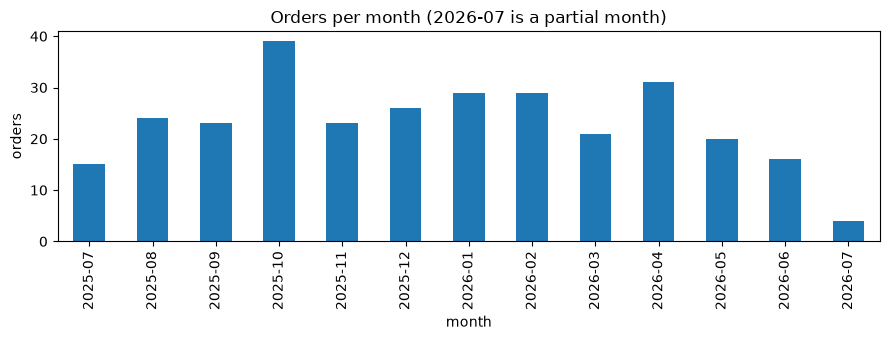

In [48]:
monthly = orders.groupby(orders["order_date"].dt.to_period("M")).size()
print(monthly.to_string())
print()
print("마지막 주문일:", orders["order_date"].max().date(), "→ 2026-07은 8일까지만 있는 부분 월입니다.")

try:
    import matplotlib.pyplot as plt
    ax = monthly.plot(kind="bar", figsize=(9, 3.5), title="Orders per month (2026-07 is a partial month)")
    ax.set_xlabel("month"); ax.set_ylabel("orders")
    plt.tight_layout(); plt.show()
except ImportError:
    print("matplotlib 미설치: 차트는 생략합니다.")

### 21-6. 점검 결과 종합표

In [49]:
findings = pd.DataFrame([
    ("전체 행 중복", int(sum(df.duplicated().sum() for df in datasets.values())), "문제 없음"),
    ("주요 ID 결측·중복", 0, "문제 없음"),
    ("FK 관계 위반", 0, "문제 없음"),
    ("날짜 변환 실패", int(orders["order_date"].isna().sum() + signup.isna().sum()), "문제 없음"),
    ("단가와 상품 가격 불일치", int((price_check["unit_price"] != price_check["price"]).sum()), "문제 없음"),
    ("가입일 이전 주문", len(before_signup), "원인 확인 필요"),
    ("같은 주문 내 동일 상품 중복 행", int(order_items.duplicated(["order_id", "product_id"]).sum()), "원인 확인 필요"),
    ("주문 이력 없는 고객", int((~customers["customer_id"].isin(orders["customer_id"])).sum()), "정상 가능, 분석 시 구분"),
], columns=["check", "count", "judgement"])
findings

,check,count,judgement
0,전체 행 중복,0,문제 없음
1,주요 ID 결측·중복,0,문제 없음
2,FK 관계 위반,0,문제 없음
3,날짜 변환 실패,0,문제 없음
4,단가와 상품 가격 불일치,0,문제 없음
5,가입일 이전 주문,56,원인 확인 필요
6,같은 주문 내 동일 상품 중복 행,10,원인 확인 필요
7,주문 이력 없는 고객,24,"정상 가능, 분석 시 구분"


---
# 제출 답안

## 1. 데이터 로딩과 구조 확인
### 실행/결과
- 4개 CSV 로딩 여부: 4개 모두 존재(`exists=True`), 오류 없이 DataFrame으로 로딩했습니다.
- 각 데이터 shape: customers (150, 6) / products (100, 4) / orders (300, 5) / order_items (764, 5)
- 주요 컬럼: `customer_id`, `product_id`, `order_id`, `order_item_id`
- dtypes에서 주목한 컬럼: `customers.signup_date`, `orders.order_date`는 날짜처럼 보이지만 문자열(`str`)입니다. 변환 후 `orders.order_date`는 `datetime64`가 되었습니다.

### Evidence
5절 shape 표, 7~8절 `columns`·`info()`·dtypes 출력 (위 Notebook 셀 참고)

### 결과 관찰
- `order_items`(764행)가 `orders`(300행)보다 많습니다. 주문당 상품 행은 평균 2.55개(최소 1, 최대 4)입니다.
- 네 데이터셋 모두 키 컬럼명이 `customer_id`, `order_id`, `product_id`로 일관됩니다.
- 숫자형은 `int64`, 이름·성별·도시·날짜는 문자열입니다.

### 나의 해석과 판단
- 날짜 컬럼이 문자열이므로 변환 전에는 월별·기간별 분석을 하면 안 됩니다. 문자열 상태에서는 정렬은 되어도 날짜 연산은 틀릴 수 있습니다.
- 분석 전에 가장 주의할 컬럼은 `order_date`, `signup_date`(날짜 변환)와 `order_status`(분석 대상 범위)입니다.

### 업무·분석적 의미
- 구조를 확인하지 않고 분석하면 ID를 숫자 평균에 포함하거나, 날짜를 문자열로 다뤄 기간 집계를 틀리게 하는 문제가 생깁니다.

### 한계와 추가 확인 사항
- 이 데이터는 생성된 샘플이라 실제 업무 데이터의 형식 불일치(공백, 표기 차이 등)는 드러나지 않았습니다. 공백 문제는 별도로 확인했으나 0건이었습니다.

## 2. 결측·중복·키 품질
- 주요 ID 결측: 0 (모든 컬럼 결측 0, 결측률 0%)
- 주요 ID 중복: `customer_id`, `product_id`, `order_id` 모두 0
- 전체 행 중복: 4개 데이터셋 모두 0

### Evidence
9~10절 결측·중복 표, 21-6 종합표

### 결과 관찰
- `order_items.order_id`는 464건이 중복으로 집계되지만 한 주문에 여러 상품이 있기 때문입니다(764 − 300 = 464). 정상입니다.
- 반면 **같은 주문 안에서 같은 상품이 중복된 행이 10건(20행)** 있습니다. 예: 주문 145의 상품 49는 수량 4, 단가 161,000으로 두 행이 동일합니다.
- 주문 이력이 없는 고객이 24명(16%), 고객 이름이 중복되는 경우가 16건(서로 다른 `customer_id`)입니다.

### 나의 해석과 판단
처리 우선순위는 다음과 같이 판단했습니다.
1. 같은 주문 내 동일 상품 중복 10건: 단순 입력 중복이면 금액이 이중 집계되므로 가장 먼저 확인해야 합니다. 수량이 다른 경우(주문 49, 65 등)는 의도된 분할 입력일 수 있어 일괄 삭제하면 안 됩니다.
2. 주문 이력 없는 고객 24명: 오류가 아니라 가입만 한 고객일 수 있어 삭제 대상이 아닙니다. 고객별 분석 시 분모를 어떻게 잡을지만 정하면 됩니다.
3. 이름 중복 16건: ID가 다르므로 동일인 여부는 이름만으로 단정할 수 없어 보류합니다.

### 업무·분석적 의미
- 전체 행 중복이 0이라는 결과만 보고 "중복 없음"이라고 결론 내리면, 키 조합 수준의 중복을 놓칩니다. 중복은 행 전체, 고유 ID, 키 조합 세 수준에서 따로 봐야 합니다.

### 한계와 추가 확인 사항
- 중복 10건이 입력 오류인지 의도된 분할인지는 데이터만으로 알 수 없고, 주문 시스템 담당자에게 확인해야 합니다.

## 3. 숫자형·범주형·날짜 점검
- 숫자형 범위에서 주목한 값: age 19~69(평균 42.1), price 5,000~200,000, quantity 1~5, unit_price 5,000~200,000. 음수나 0은 없습니다.
- 범주형 빈도에서 주목한 값: `order_status`는 completed 184(61.3%) / cancelled 64(21.3%) / refunded 52(17.3%). 도시 10종, 상품 카테고리 7종, 결제수단 4종, 성별 F 84 / M 66
- 날짜 변환 실패 건수: `order_date` 0, `signup_date` 0
- 날짜 범위: 주문일 2025-07-09 ~ 2026-07-08, 가입일 2023-07-14 ~ 2026-06-27

### Evidence
11~13절 `describe()`·`value_counts()`·날짜 변환 출력, 21-5 상태·월별 표와 차트

### 결과 관찰
- 금액 기준으로 보면 completed 148,990,000원(58.3%), cancelled 62,181,000원(24.3%), refunded 44,439,000원(17.4%)이고, 전체 합계는 255,610,000원입니다.
- 월별 주문 수는 2025-10이 39건으로 가장 많고 2026-06은 16건입니다. 2026-07은 4건뿐인데 마지막 주문일이 07-08이라 **8일치만 있는 부분 월**입니다.
- **가입일보다 이른 주문이 56건(18.7%)** 있습니다. 예: 주문 19는 2025-11-25에 주문했는데 고객 6의 가입일은 2026-06-27입니다.

### 나의 해석과 판단
- 취소·환불이 건수 기준 약 39%, 금액 기준 약 42%라서 매출 분석 전에 포함 범위를 정해야 합니다. 정하지 않고 합계를 내면 실제 매출보다 약 1.7배 큰 값(255.6M vs 149.0M)이 나옵니다.
- 가입일 이후 주문이어야 한다는 업무 규칙이 있다면 56건은 오류입니다. 샘플 생성 시 두 날짜를 독립적으로 만들었을 가능성이 높지만, 실제 데이터였다면 가입일 컬럼의 의미(최초 가입일인지 재가입일인지)부터 확인해야 합니다.
- 월별 추이를 볼 때 2026-07을 그대로 쓰면 급감한 것처럼 잘못 읽게 되므로 제외하거나 부분 월로 표시해야 합니다.
- 값의 범위 자체에는 이상치로 볼 값이 없었습니다(단가는 상품 마스터 가격과 전부 일치).

### 업무·분석적 의미
- 날짜 변환이 성공했다는 사실과 날짜가 논리적으로 맞다는 사실은 다릅니다. 변환 실패 0건이어도 날짜 간 선후 관계를 별도로 검증해야 합니다.

### 한계와 추가 확인 사항
- 12개월치라 계절성은 한 주기만 볼 수 있어 10월 급증이 계절 효과인지 우연인지 판단할 수 없습니다.
- 가입일 이전 주문의 원인(비회원 주문, 이관, 데이터 오류)은 데이터만으로 알 수 없습니다.

## 4. CSV 간 키 관계 검증
- 없는 `customer_id`: 0 (`orders` → `customers`)
- 없는 `order_id`: 0 (`order_items` → `orders`)
- 없는 `product_id`: 0 (`order_items` → `products`)

### Evidence
14절 키 관계 검증 표, 21-2·21-4 보조 검증

### 결과 관찰
- 세 연결 모두 부모 테이블에 없는 ID가 없습니다.
- 보조로 확인한 결과: 주문 상세가 없는 주문 0건, 한 번도 팔리지 않은 상품 0개, 단가와 상품 마스터 가격 불일치 0건입니다.

### 나의 해석과 판단
- join을 해도 행이 유실되지 않는 상태라 병합 분석을 진행해도 됩니다.
- 만약 위반이 발견되었다면 바로 삭제하면 안 됩니다. 파일 누락, ID 타입 차이, 앞뒤 공백, 수집 시점 차이 등 원인에 따라 조치가 달라지고, 삭제하면 매출 집계에서 해당 주문이 조용히 빠지기 때문입니다.

### 업무·분석적 의미
- 키 관계가 맞지 않은 채 `how="inner"`로 join하면 행이 사라져도 오류가 나지 않아 결과가 틀린 것을 알아채기 어렵습니다. join 전후의 행 수를 비교하는 습관이 필요합니다.

### 한계와 추가 확인 사항
- ID 존재 여부만 확인했습니다. 값의 일관성(주문 금액 합계와 상세 합계 일치)은 확인하지 못했습니다.

## 5. LLM 구조 설명 검증
- 사용한 LLM: Claude(Claude Code, 모델 Claude Sonnet 5.5)
- LLM에 제공한 Safe Context: 이번에는 Claude Code가 로컬 폴더의 샘플 CSV에 직접 접근해 노트북을 실행했습니다. 데이터는 강의용으로 생성된 가상 샘플이라 개인정보가 없습니다. 실제 업무 데이터라면 파일명, 행·열 수, 컬럼명, dtypes, 결측·중복 건수, 키 관계 요약만 제공해야 합니다.
- LLM이 제안한 추가 점검과 직접 확인 결과:

| LLM 제안 | 실제 확인 셀 | 결과 |
|---|---|---|
| 날짜 컬럼 변환 후 선후 관계 확인 | 21-1 | 가입일 이전 주문 56건 발견 |
| 주문 상세 단가와 상품 가격 일치 | 21-2 | 불일치 0건 |
| 키 조합 수준 중복 확인 | 21-3 | 같은 주문 내 동일 상품 10건 발견 |
| 주문 없는 고객, 상세 없는 주문 확인 | 21-4 | 고객 24명 / 주문 0건 |
| 취소·환불 비중 확인 | 21-5 | 건수 약 39%, 금액 약 42% |
| 마지막 달이 완전한 월인지 확인 | 21-5 | 2026-07은 8일치 |

- 채택/수정/보류한 내용:
  - 채택: 위 6개 점검 모두 실제 코드로 실행했습니다.
  - 수정: LLM이 처음에는 "중복 없음"으로 정리하기 쉬운 지점(행 전체 중복 0)을 키 조합 수준까지 내려가 보도록 수정했고, 그 결과 10건을 찾았습니다.
  - 보류: 이름 중복 16건의 동일인 여부, 가입일 이전 주문의 원인은 데이터만으로 판단할 수 없어 보류했습니다.

### 나의 해석과 판단
- 가장 유용했던 것은 "값이 비어 있지 않다"에서 멈추지 않고 날짜 선후, 단가 일치처럼 **업무 규칙 수준의 검증**을 제안받은 점입니다. 이 과정에서 56건과 10건을 찾았습니다.
- 조심할 점은 LLM의 설명이 그럴듯해도 실제 컬럼·값과 다를 수 있다는 것입니다. 18절처럼 `age` 컬럼 존재 여부, 결측 개수, 키 연결을 코드로 확인한 뒤에만 사용했습니다.

### 한계와 추가 확인 사항
- 구조 요약만 받은 LLM은 56건·10건 같은 구체적 이상을 스스로 알 수 없습니다. 이번에는 Claude Code가 데이터에 접근해 직접 실행했기 때문에 찾을 수 있었고, 실제 업무 데이터에서는 이상 탐지를 로컬에서 직접 실행한 결과로 확인해야 합니다.

## 6. Chapter 03 최종 판단
### 데이터의 첫인상 3가지
1. 구조는 깨끗합니다. 결측 0, 전체 행·ID 중복 0, 키 관계 위반 0, 날짜 변환 실패 0이고 단가도 상품 가격과 모두 일치합니다.
2. 하지만 업무 규칙 수준에서는 이상이 있습니다. 가입일보다 이른 주문 56건(18.7%), 같은 주문 내 동일 상품 중복 10건이 있습니다.
3. 주문의 39%(금액의 42%)가 취소·환불이라 분석 기준을 정하지 않으면 매출이 약 1.7배로 부풀려집니다.

### 다음 Chapter 전에 반드시 확인/처리해야 할 항목
1. `signup_date`, `order_date` 날짜형 변환 (`order_date`는 이미 변환, `signup_date`는 분석 시 변환)
2. 분석에 포함할 `order_status` 기준 결정 (예: completed만 매출로 집계)
3. 동일 주문 내 동일 상품 10건과 가입일 이전 주문 56건의 처리 방침 결정 (삭제하지 말고 플래그 컬럼으로 표시)
4. 2026-07 부분 월 제외 여부 결정

### 현재 데이터만으로 단정할 수 없는 것
- 가입일 이전 주문 56건과 동일 상품 중복 10건이 오류인지 정상 업무 흐름인지
- 이름이 같은 고객 16건이 동일인인지
- 10월 주문 급증이 계절성인지 우연인지
- 이 샘플 데이터의 품질이 실제 업무 데이터에도 해당하는지

## 최종 제출 체크
- [x] Notebook을 처음부터 끝까지 실행했습니다.
- [x] 오류 셀이 남아 있지 않습니다.
- [x] 핵심 Evidence는 Notebook 출력(표·차트)으로 첨부했습니다.
- [x] 관찰과 해석을 구분했습니다.
- [x] 개인정보/Secret이 없습니다(샘플 데이터).
- [ ] `chapter03/chapter03.ipynb`가 GitHub에서 정상 표시되는지 업로드 후 확인
- [ ] 최종 Notebook 파일 URL 제출